# MODELIZACIÓN CLASIFICACIÓN PROBABILITY OF DEFAULT

## IMPORTAR PAQUETES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import os
from pathlib import Path
import openpyxl
import sqlalchemy as sa

# Desactivar notación científica
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

#RUTAS
# ── Rutas del proyecto ────────────────────────────────────────────────
# Se resuelven desde la ubicación del notebook, así funcionan
# igual en cualquier máquina
RAIZ = Path.cwd().parent

ORIGINALES   = RAIZ / '02_datos' / '01_Originales'
VALIDACION   = RAIZ / '02_datos' / '02_Validacion'
ENTRENAMIENTO = RAIZ / '02_datos' / '03_Entrenamiento'
CACHES       = RAIZ / '02_datos' / '04_Caches'
MODELOS      = RAIZ / '05_modelos'
RESULTADOS   = RAIZ / '06_resultados'

# ----------USO DE UTILS.PY------------
import sys
from pathlib import Path
# Subir de 03_notebooks a 03_RIESGOS
ROOT = Path.cwd().parent
# Añadir 04_scripts a las rutas de búsqueda
sys.path.insert(0, str(ROOT / "04_scripts"))
#---------------------------------------

# Cargar variables de entorno
load_dotenv()

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


## MODELIZACIÓN CLASIFICACIÓN PROBABILITY OF DEFAULT

### IMPORTAR LOS DATOS

In [2]:
df = pd.read_pickle(ENTRENAMIENTO /'df_tablon_pd.pkl')

In [3]:
x = df.drop(columns='target_pd')
y = df.target_pd

### MODELIZAR

#### Reservar el dataset de validacion

In [4]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x, y, test_size=0.3, random_state=42, stratify=y)

In [5]:
#mejor nomenclatura de nombres, conjunto de validacion no es lo mismo que el conjunto de testeo,
#  el conjunto de validacion es para ajustar hiperparametros y el conjunto de testeo es para..
#  evaluar el modelo final

y_val = y_test
x_val = x_test

#### Crear el pipe y el diccionario de algorimos, parámetros y valores a testar

Modificar para dejar solo los algoritmos que se quieran testar.

Modificar los parámetros.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([('algoritmo', LogisticRegression())])   # el nombre del paso es solo una etiqueta fija

grid = [{
    # solver saga: es el único que admite L1 y ElasticNet (el de por defecto solo L2)
    # max_iter alto: saga tarda en converger
    'algoritmo': [LogisticRegression(solver='saga', max_iter=5000)],

    # l1_ratio (penalty está obsoleto desde Sklearn 1.8):
    #   0   Ridge: encoge todos los coeficientes, ayuda con multicolinealidad
    #   0.5 ElasticNet: mezcla, útil con variables correlacionadas entre sí
    #   1   Lasso: lleva coeficientes a cero, hace preselección de variables
    'algoritmo__l1_ratio': [0, 0.5, 1],

    # C es la inversa de la fuerza: C pequeño penaliza mucho, C grande poco
    'algoritmo__C': [0.01, 0.05, 0.1, 0.25, 0.75, 1]
}]


#### Optimizar los hiper parámetros

#####  Con grid search

In [7]:
Gs = GridSearchCV(estimator=pipe,
                  param_grid=grid,
                  cv=5,scoring='roc_auc',
                  verbose=0,
                  n_jobs=-1)
modelo = Gs.fit(x_train,y_train)


In [8]:
salida = pd.DataFrame(Gs.cv_results_).sort_values(by='rank_test_score').reset_index(drop=True).head(5)
salida

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_algoritmo,param_algoritmo__C,param_algoritmo__l1_ratio,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.692,0.044,0.011,0.001,"LogisticRegression(max_iter=5000, solver='saga')",0.250,1.000,{'algoritmo': LogisticRegression(max_iter=5000...,0.699,0.702,0.696,0.696,0.702,0.699,0.003,1
1,0.651,0.061,0.011,0.000,"LogisticRegression(max_iter=5000, solver='saga')",0.250,0.500,{'algoritmo': LogisticRegression(max_iter=5000...,0.699,0.702,0.696,0.696,0.702,0.699,0.003,2
2,0.729,0.061,0.010,0.001,"LogisticRegression(max_iter=5000, solver='saga')",0.750,1.000,{'algoritmo': LogisticRegression(max_iter=5000...,0.699,0.702,0.696,0.696,0.702,0.699,0.003,3
3,0.686,0.033,0.011,0.001,"LogisticRegression(max_iter=5000, solver='saga')",1.000,1.000,{'algoritmo': LogisticRegression(max_iter=5000...,0.699,0.702,0.696,0.696,0.702,0.699,0.003,4
4,0.962,0.309,0.013,0.002,"LogisticRegression(max_iter=5000, solver='saga')",0.750,0.500,{'algoritmo': LogisticRegression(max_iter=5000...,0.699,0.702,0.696,0.696,0.702,0.699,0.003,5




Vemos que el resultados del auc es el mismo en todas las primeras configuraciones.

Y reentreamos el modelo con esa configuración.

In [9]:

#Instancia y entrena el modelo con los mejores hiperparámetros
m = LogisticRegression(solver='saga', l1_ratio=1, C=0.05, max_iter=5000).fit(x_train, y_train)
pd.Series(m.coef_[0], index=x_train.columns).sort_values()

ingresos_scaled                        -1.094
ingresos_verificados_Not Verified      -0.253
finalidad_other                        -0.122
antiguedad_empleo_scaled               -0.061
vivienda_MORTGAGE                      -0.059
finalidad_credit_card                  -0.012
finalidad_car                           0.000
vivienda_OWN                            0.000
finalidad_moving                        0.000
finalidad_house                         0.000
finalidad_medical                       0.000
num_cuotas_ 60 months                   0.000
finalidad_vacation                      0.000
num_cuotas_ 36 months                   0.000
finalidad_major_purchase                0.000
ingresos_verificados_Source Verified    0.000
dti_scaled                              0.009
finalidad_small_business                0.011
finalidad_home_improvement              0.018
finalidad_debt_consolidation            0.036
principal_scaled                        0.039
ingresos_verificados_Verified     

**Decisión (31/10/2026): la tasa de interés y la cuota quedan fuera del modelo.** En la versión anterior `tipo_interes` e `imp_cuota` entraban como predictoras. Pero la tasa la fija el banco al conceder, a partir del riesgo del cliente, así que usarla para predecir ese mismo riesgo es circular. Además la tasa casi coincide con el rating (correlación 0,953) y el Lasso repartía el peso con signos opuestos: con el mismo cliente, subir la tasa bajaba la PD. `imp_cuota` se descarta también porque se calcula con la tasa. Con validación cruzada sobre el 70 %, el AUC de la PD pasó de 0,7002 a 0,6976, dentro del ruido (±0,005). La tasa pasa a ser una respuesta de la API (tasa sugerida), no una entrada.

### EVALUAR

#### Predecir sobre validación

In [10]:
pred_val = m.predict_proba(x_test)[:,1]

#### Evaluar sobre validación

In [11]:
from sklearn.metrics import roc_auc_score, roc_curve, auc
roc_auc_score(y_val, pred_val)

0.6935410534921174

### REPORTING DEL MODELO

Funciones a usar

In [12]:
def plot_gain_multi(y, probas, labels=None):
    y = np.asarray(y).ravel()
    if labels is None:
        labels = []
        for i in range(len(probas)):
            labels.append(f"Modelo {i+1}")

    n = len(y)
    x_pct = np.arange(1, n+1) / n

    plt.figure()
    for proba, lab in zip(probas, labels):
        p = np.asarray(proba)
        if p.ndim == 2:
            p = p[:, 1]
        order = np.argsort(-p)
        y_sorted = y[order]
        gain = np.cumsum(y_sorted) / max(y.sum(), 1)
        plt.plot(x_pct, gain, label=lab)

    plt.plot([0, 1], [0, 1], "--", label="Aleatoria")
    plt.xlabel("% observaciones"); plt.ylabel("% objetivo acumulado")
    plt.title("Curva de Ganancia Acumulada")
    plt.legend()
    plt.grid()
    plt.show();

def plot_lift_multi(y, probas, labels=None):
    y = np.asarray(y).ravel()
    if labels is None:
        labels = []
        for i in range(len(probas)):
            labels.append(f"Modelo {i+1}")

    n = len(y)
    x_pct = np.arange(1, n+1) / n

    plt.figure()
    for proba, lab in zip(probas, labels):
        p = np.asarray(proba)
        if p.ndim == 2:
            p = p[:, 1]
        order = np.argsort(-p)
        y_sorted = y[order]
        gain = np.cumsum(y_sorted) / max(y.sum(), 1)
        lift = gain / x_pct
        plt.plot(x_pct, lift, label=lab)

    plt.axhline(1, linestyle="--", color="gray", label="Aleatorio")
    plt.xlabel("% observaciones"); plt.ylabel("Lift")
    plt.title("Curva de Lift")
    plt.legend()
    plt.grid(True)
    plt.show();


def de_logit_a_prob(modelo, test_x):
    logit = modelo.intercept_ + np.sum(modelo.coef_ * test_x, axis=1)
    return 1 / (1 + np.exp(-logit))

#### Gain Chart

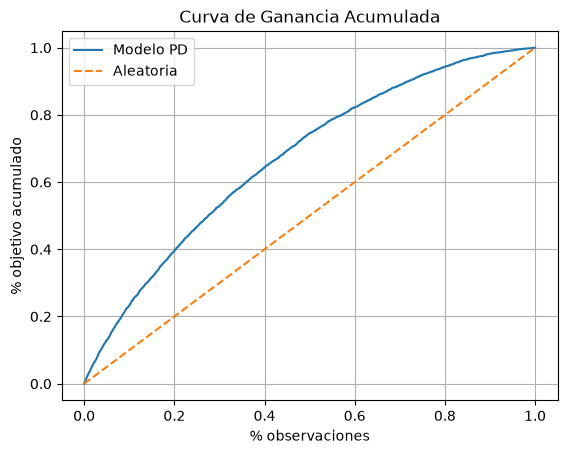

In [13]:
plot_gain_multi(y_val, [pred_val], labels=["Modelo PD"])

#### Lift Chart

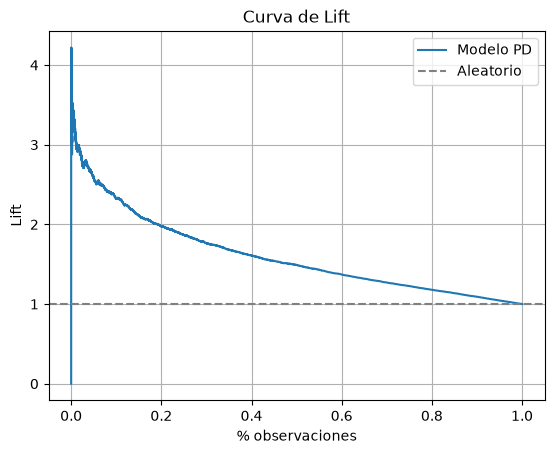

In [14]:
plot_lift_multi(y_val, [pred_val], labels=["Modelo PD"])

#### ROC Chart

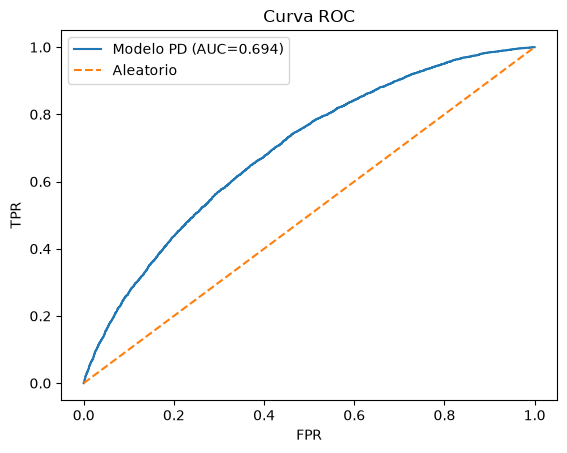

In [15]:
from utils import plot_roc_multi_np
plot_roc_multi_np(y_val, [pred_val], labels=["Modelo PD"])